In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("../Dataset/retail_sales.csv")

In [ ]:
df = pd.read_csv(r"C:\Users\Dell\Retail-Sales-Analysis\Dataset\retail_sales.csv")


In [ ]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nDoes the dataset exist?")
print(os.path.exists(r"C:\Users\Dell\Retail-Sales-Analysis\Dataset\retail_sales.csv"))

print("\nFiles in Dataset folder:")
print(os.listdir(r"C:\Users\Dell\Retail-Sales-Analysis\Dataset"))


In [ ]:
df = pd.read_csv(r"C:\Users\Dell\Retail-Sales-Analysis\Dataset\retail_sales.csv")

In [ ]:
df.head()

In [ ]:
df.shape

In [ ]:
df.info()


In [ ]:
df.describe()

In [ ]:
df.isnull().sum()

In [ ]:
df.duplicated().sum()

In [ ]:
df.isnull().sum()

In [ ]:
df.drop(columns=['Unnamed: 0'], inplace=True)

In [ ]:
df['Date'] = pd.to_datetime(df['Date'])

In [ ]:
df.info()

In [ ]:
df.head()

In [ ]:
df.to_csv(r"C:/Users/Dell/Retail-Sales-Analysis/Dataset/cleaned_retail_sales.csv", index=False)

In [ ]:
df.info()


In [ ]:
df.duplicated().sum()

In [ ]:
df['Age'].describe()

In [ ]:
df['Quantity'].value_counts().sort_index()

In [ ]:
df['Product Category'].value_counts()

In [ ]:
(df['Quantity'] * df['Price per Unit'] == df['Total Amount']).value_counts()

In [ ]:
df_eda = df.copy()

In [ ]:
df_eda['Year'] = df_eda['Date'].dt.year

df_eda['Month'] = df_eda['Date'].dt.month_name()

df_eda['Day'] = df_eda['Date'].dt.day_name()

In [ ]:
df_eda.head()

In [ ]:
total_revenue = df_eda['Total Amount'].sum()
print("Total Revenue:", total_revenue)

In [ ]:
total_transactions = len(df_eda)
print("Total Transactions:", total_transactions)

In [ ]:
average_order_value = df_eda['Total Amount'].mean()
print("Average Order Value:", average_order_value)

In [ ]:
total_quantity = df_eda['Quantity'].sum()
print("Total Quantity Sold:", total_quantity)

In [ ]:
average_age = df_eda['Age'].mean()
print("Average Customer Age:", average_age)

In [ ]:
monthly_sales = df_eda.groupby('Month')['Total Amount'].sum()
print(monthly_sales)

In [ ]:
monthly_sales = df_eda.groupby(
    df_eda['Date'].dt.month
)['Total Amount'].sum()

print(monthly_sales)

In [ ]:
highest_month = monthly_sales.idxmax()
highest_revenue = monthly_sales.max()

print("Highest Sales Month:", highest_month)
print("Highest Revenue:", highest_revenue)

In [ ]:
lowest_month = monthly_sales.idxmin()
lowest_revenue = monthly_sales.min()

print("Lowest Sales Month:", lowest_month)
print("Lowest Revenue:", lowest_revenue)

In [ ]:
import matplotlib.pyplot as plt

monthly_sales.plot(kind='bar', figsize=(10,5))

plt.title('Monthly Revenue Analysis')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.show()

In [ ]:
category_sales = df_eda.groupby('Product Category')['Total Amount'].sum()

print(category_sales)

In [ ]:
highest_category = category_sales.idxmax()

print("Highest Revenue Category:", highest_category)
print("Revenue:", category_sales.max())

In [ ]:
lowest_category = category_sales.idxmin()

print("Lowest Revenue Category:", lowest_category)
print("Revenue:", category_sales.min())

In [ ]:
category_quantity = df_eda.groupby('Product Category')['Quantity'].sum()

print(category_quantity)

In [ ]:
import matplotlib.pyplot as plt

category_sales.plot(kind='bar', figsize=(8,5))

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.show()

In [ ]:
category_sales.plot(kind='pie', autopct='%1.1f%%', figsize=(7,7))

plt.title('Revenue Contribution by Category')
plt.ylabel('')
plt.show()

In [ ]:
gender_count = df_eda['Gender'].value_counts()

print(gender_count)

In [ ]:
gender_sales = df_eda.groupby('Gender')['Total Amount'].sum()

print(gender_sales)

In [ ]:
gender_average = df_eda.groupby('Gender')['Total Amount'].mean()

print(gender_average)

In [ ]:
gender_quantity = df_eda.groupby('Gender')['Quantity'].sum()

print(gender_quantity)

In [ ]:
import matplotlib.pyplot as plt

gender_sales.plot(kind='bar', figsize=(7,5))

plt.title('Revenue by Gender')
plt.xlabel('Gender')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.show()

In [ ]:
gender_count.plot(kind='pie', autopct='%1.1f%%', figsize=(6,6))

plt.title('Customer Distribution by Gender')
plt.ylabel('')
plt.show()

In [ ]:
bins = [17, 25, 35, 45, 55, 65]

labels = ['18-25', '26-35', '36-45', '46-55', '56-64']

df_eda['Age Group'] = pd.cut(
    df_eda['Age'],
    bins=bins,
    labels=labels
)

In [ ]:
age_count = df_eda['Age Group'].value_counts().sort_index()

print(age_count)

In [ ]:
age_revenue = df_eda.groupby(
    'Age Group', observed=False
)['Total Amount'].sum()

print(age_revenue)

In [ ]:
age_average = df_eda.groupby(
    'Age Group', observed=False
)['Total Amount'].mean()

print(age_average)

In [ ]:
print("Highest Revenue Age Group:", age_revenue.idxmax())

print("Highest Revenue:", age_revenue.max())

In [ ]:
import matplotlib.pyplot as plt

age_revenue.plot(kind='bar', figsize=(9,5))

plt.title('Revenue by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.show()

In [ ]:
age_count.plot(kind='pie', autopct='%1.1f%%', figsize=(7,7))

plt.title('Customer Distribution by Age Group')
plt.ylabel('')
plt.show()

In [ ]:
category_gender_count = pd.crosstab(
    df_eda['Product Category'],
    df_eda['Gender']
)

print(category_gender_count)

In [ ]:
category_gender_sales = df_eda.pivot_table(
    index='Product Category',
    columns='Gender',
    values='Total Amount',
    aggfunc='sum'
)

print(category_gender_sales)

In [ ]:
category_gender_quantity = df_eda.pivot_table(
    index='Product Category',
    columns='Gender',
    values='Quantity',
    aggfunc='sum'
)

print(category_gender_quantity)

In [ ]:
import matplotlib.pyplot as plt

category_gender_sales.plot(
    kind='bar',
    figsize=(9,5)
)

plt.title('Product Category Revenue by Gender')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.legend(title='Gender')
plt.show()

In [ ]:
category_gender_count.plot(
    kind='bar',
    figsize=(9,5)
)

plt.title('Customer Count by Product Category and Gender')
plt.xlabel('Product Category')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.legend(title='Gender')
plt.show()

In [ ]:
daily_sales = df_eda.groupby('Day')['Total Amount'].sum()

print(daily_sales)

In [ ]:
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_sales = daily_sales.reindex(day_order)

print(daily_sales)

In [ ]:
highest_day = daily_sales.idxmax()

print("Highest Sales Day:", highest_day)
print("Revenue:", daily_sales.max())

In [ ]:
daily_transactions = df_eda.groupby('Day').size()

daily_transactions = daily_transactions.reindex(day_order)

print(daily_transactions)

In [ ]:
daily_average = df_eda.groupby('Day')['Total Amount'].mean()

daily_average = daily_average.reindex(day_order)

print(daily_average)

In [ ]:
import matplotlib.pyplot as plt

daily_sales.plot(kind='bar', figsize=(10,5))

plt.title('Daily Revenue Analysis')
plt.xlabel('Day of the Week')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.show()

In [ ]:
daily_transactions.plot(kind='line', marker='o', figsize=(10,5))

plt.title('Daily Transaction Analysis')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)
plt.grid()
plt.show()

In [ ]:
monthly_trend = df_eda.groupby(
    df_eda['Date'].dt.to_period('M')
)['Total Amount'].sum()

print(monthly_trend)

In [71]:
monthly_trend.index = monthly_trend.index.astype(str)

print(monthly_trend)

Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Name: Total Amount, dtype: int64


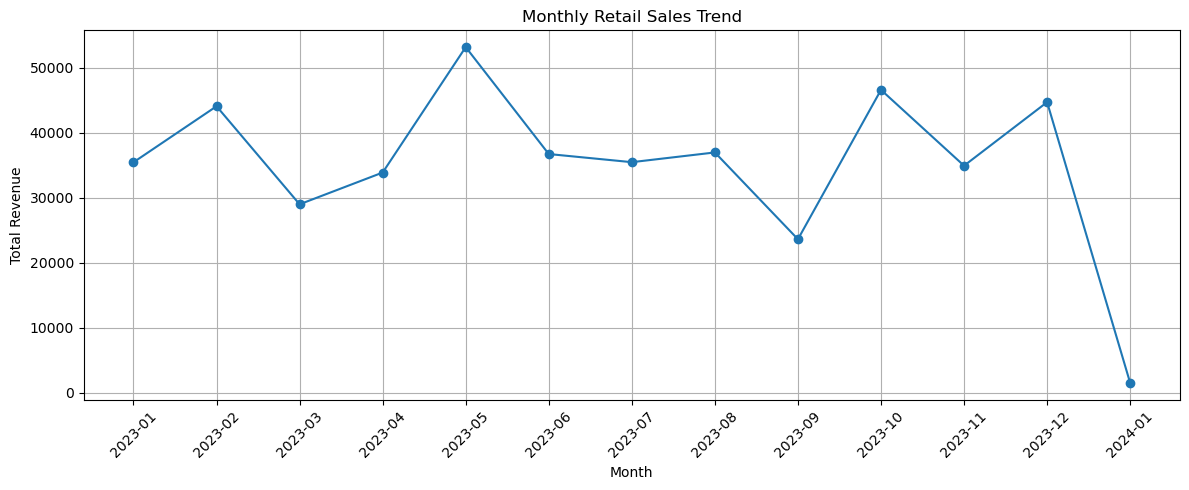

In [72]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(
    monthly_trend.index,
    monthly_trend.values,
    marker='o'
)

plt.title('Monthly Retail Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

In [73]:
quarterly_sales = df_eda.groupby(
    df_eda['Date'].dt.to_period('Q')
)['Total Amount'].sum()

print(quarterly_sales)

Date
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64


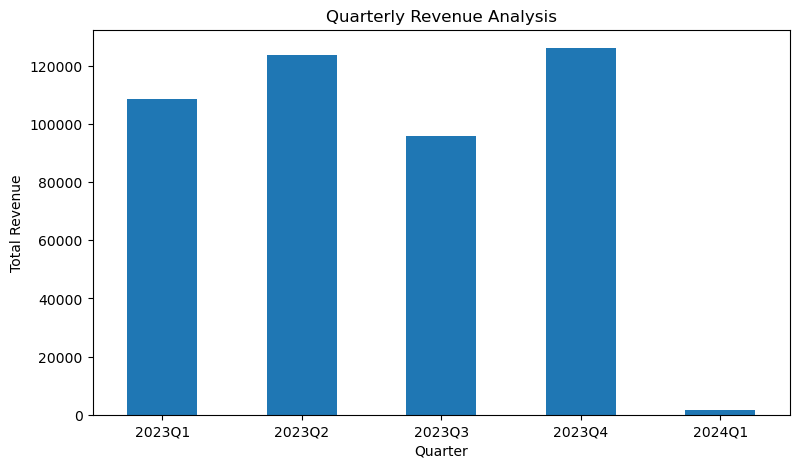

In [74]:
quarterly_sales.plot(
    kind='bar',
    figsize=(9,5)
)

plt.title('Quarterly Revenue Analysis')
plt.xlabel('Quarter')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.show()

In [75]:
avg_price = df_eda.groupby('Product Category')['Price per Unit'].mean()

print(avg_price)

Product Category
Beauty         184.055375
Clothing       174.287749
Electronics    181.900585
Name: Price per Unit, dtype: float64


In [76]:
total_quantity = df_eda.groupby('Product Category')['Quantity'].sum()

print(total_quantity)

Product Category
Beauty         771
Clothing       894
Electronics    849
Name: Quantity, dtype: int64


In [77]:
avg_quantity = df_eda.groupby('Product Category')['Quantity'].mean()

print(avg_quantity)

Product Category
Beauty         2.511401
Clothing       2.547009
Electronics    2.482456
Name: Quantity, dtype: float64


In [78]:
revenue_per_unit = df_eda.groupby('Product Category').apply(
    lambda x: x['Total Amount'].sum() / x['Quantity'].sum()
)

print(revenue_per_unit)

Product Category
Beauty         186.141375
Clothing       174.026846
Electronics    184.811543
dtype: float64


C:\Users\Dell\AppData\Local\Temp\ipykernel_1908\1929561492.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  revenue_per_unit = df_eda.groupby('Product Category').apply(


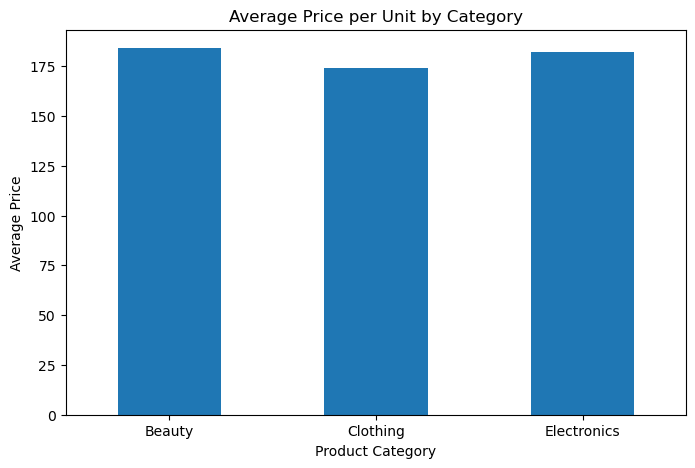

In [79]:
import matplotlib.pyplot as plt

avg_price.plot(kind='bar', figsize=(8,5))

plt.title('Average Price per Unit by Category')
plt.xlabel('Product Category')
plt.ylabel('Average Price')
plt.xticks(rotation=0)
plt.show()

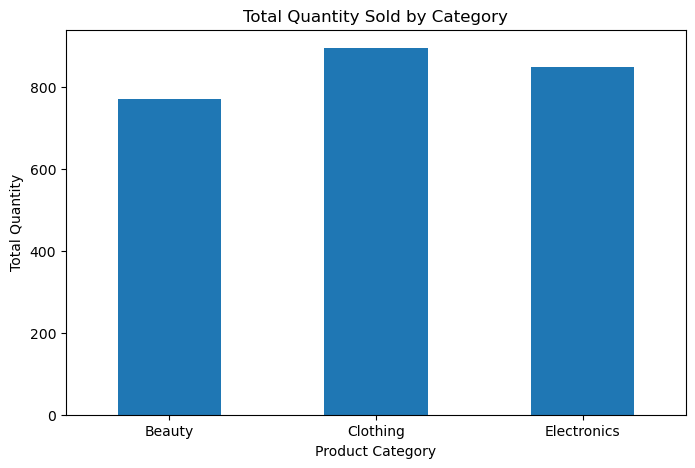

In [80]:
total_quantity.plot(kind='bar', figsize=(8,5))

plt.title('Total Quantity Sold by Category')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity')
plt.xticks(rotation=0)
plt.show()

In [81]:
df_eda.describe()


,Date,Age,Quantity,Price per Unit,Total Amount,Year
count,1000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,2023-07-03 00:25:55.200000256,41.39200,2.514000,179.890000,456.000000,2023.002000
min,2023-01-01 00:00:00,18.00000,1.000000,25.000000,25.000000,2023.000000
25%,2023-04-08 00:00:00,29.00000,1.000000,30.000000,60.000000,2023.000000
50%,2023-06-29 12:00:00,42.00000,3.000000,50.000000,135.000000,2023.000000
75%,2023-10-04 00:00:00,53.00000,4.000000,300.000000,900.000000,2023.000000
max,2024-01-01 00:00:00,64.00000,4.000000,500.000000,2000.000000,2024.000000
std,NaN,13.68143,1.132734,189.681356,559.997632,0.044699


In [82]:
Q1 = df_eda['Total Amount'].quantile(0.25)
Q3 = df_eda['Total Amount'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 60.0
Q3: 900.0
IQR: 840.0
Lower Limit: -1200.0
Upper Limit: 2160.0


In [83]:
outliers = df_eda[
    (df_eda['Total Amount'] < lower_limit) |
    (df_eda['Total Amount'] > upper_limit)
]

print("Number of Outliers:", len(outliers))
outliers.head()

Number of Outliers: 0


,Date,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Year,Month,Day,Age Group


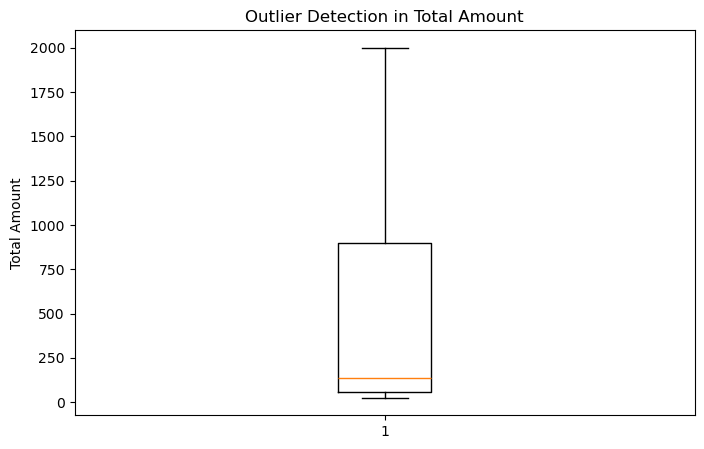

In [84]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.boxplot(df_eda['Total Amount'])

plt.title('Outlier Detection in Total Amount')
plt.ylabel('Total Amount')

plt.show()

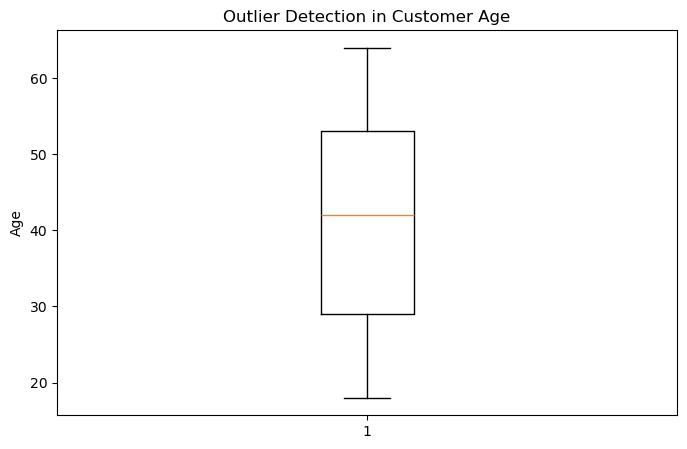

In [85]:
plt.figure(figsize=(8,5))

plt.boxplot(df_eda['Age'])

plt.title('Outlier Detection in Customer Age')
plt.ylabel('Age')

plt.show()


In [86]:
numerical_df = df_eda.select_dtypes(include='number')

print(numerical_df.head())

   Age  Quantity  Price per Unit  Total Amount  Year
0   34         3              50           150  2023
1   26         2             500          1000  2023
2   50         1              30            30  2023
3   37         1             500           500  2023
4   30         2              50           100  2023


In [87]:
correlation = numerical_df.corr()

print(correlation)

                     Age  Quantity  Price per Unit  Total Amount      Year
Age             1.000000 -0.023737       -0.038423     -0.060568  0.023269
Quantity       -0.023737  1.000000        0.017501      0.373707 -0.020324
Price per Unit -0.038423  0.017501        1.000000      0.851925  0.020097
Total Amount   -0.060568  0.373707        0.851925      1.000000  0.024714
Year            0.023269 -0.020324        0.020097      0.024714  1.000000


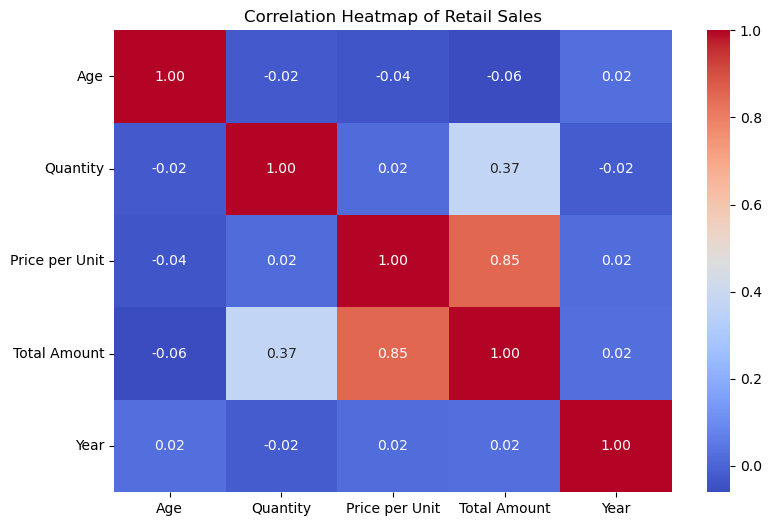

In [88]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Retail Sales')
plt.show()

In [89]:
quantity_correlation = df_eda[
    ['Quantity', 'Total Amount']
].corr()

print(quantity_correlation)

              Quantity  Total Amount
Quantity      1.000000      0.373707
Total Amount  0.373707      1.000000


In [90]:
age_correlation = df_eda[
    ['Age', 'Total Amount']
].corr()

print(age_correlation)

                   Age  Total Amount
Age           1.000000     -0.060568
Total Amount -0.060568      1.000000


In [91]:
eda_summary = {
    'Total Revenue': df_eda['Total Amount'].sum(),
    'Total Transactions': len(df_eda),
    'Total Quantity Sold': df_eda['Quantity'].sum(),
    'Average Order Value': df_eda['Total Amount'].mean(),
    'Average Customer Age': df_eda['Age'].mean()
}

for key, value in eda_summary.items():
    print(key, ":", round(value, 2))

Total Revenue : 456000
Total Transactions : 1000
Total Quantity Sold : 2514
Average Order Value : 456.0
Average Customer Age : 41.39


In [92]:
top_category = df_eda.groupby(
    'Product Category'
)['Total Amount'].sum().idxmax()

print("Top Product Category:", top_category)

Top Product Category: Electronics


In [93]:
top_gender = df_eda.groupby(
    'Gender'
)['Total Amount'].sum().idxmax()

print("Highest Revenue Gender:", top_gender)

Highest Revenue Gender: Female


In [94]:
top_age_group = df_eda.groupby(
    'Age Group', observed=False
)['Total Amount'].sum().idxmax()

print("Top Age Group:", top_age_group)

Top Age Group: 46-55


In [95]:
top_month = df_eda.groupby(
    df_eda['Date'].dt.month_name()
)['Total Amount'].sum()

print("Highest Revenue Month:", top_month.idxmax())
print("Highest Monthly Revenue:", top_month.max())

Highest Revenue Month: May
Highest Monthly Revenue: 53150


In [96]:
insights = pd.DataFrame({
    'Analysis': [
        'Product Category',
        'Gender',
        'Age Group',
        'Month'
    ],
    'Top Performer': [
        top_category,
        top_gender,
        top_age_group,
        top_month.idxmax()
    ]
})

print(insights)

           Analysis Top Performer
0  Product Category   Electronics
1            Gender        Female
2         Age Group         46-55
3             Month           May


In [97]:
total_revenue = df_eda['Total Amount'].sum()
total_transactions = len(df_eda)
total_quantity = df_eda['Quantity'].sum()
average_order_value = df_eda['Total Amount'].mean()
average_customer_age = df_eda['Age'].mean()

print("Total Revenue:", total_revenue)
print("Total Transactions:", total_transactions)
print("Total Quantity Sold:", total_quantity)
print("Average Order Value:", round(average_order_value, 2))
print("Average Customer Age:", round(average_customer_age, 2))

Total Revenue: 456000
Total Transactions: 1000
Total Quantity Sold: 2514
Average Order Value: 456.0
Average Customer Age: 41.39


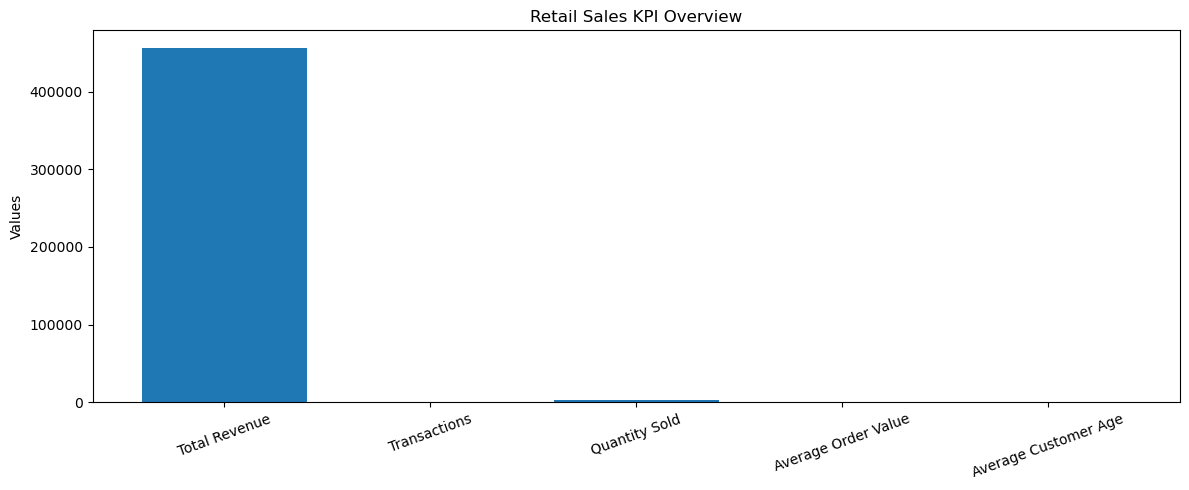

In [98]:
import matplotlib.pyplot as plt

kpi_names = [
    'Total Revenue',
    'Transactions',
    'Quantity Sold',
    'Average Order Value',
    'Average Customer Age'
]

kpi_values = [
    total_revenue,
    total_transactions,
    total_quantity,
    average_order_value,
    average_customer_age
]

plt.figure(figsize=(12, 5))

plt.bar(kpi_names, kpi_values)

plt.title('Retail Sales KPI Overview')
plt.ylabel('Values')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [99]:
monthly_revenue = df_eda.groupby(
    df_eda['Date'].dt.month
)['Total Amount'].sum()

print(monthly_revenue)

Date
1     36980
2     44060
3     28990
4     33870
5     53150
6     36715
7     35465
8     36960
9     23620
10    46580
11    34920
12    44690
Name: Total Amount, dtype: int64


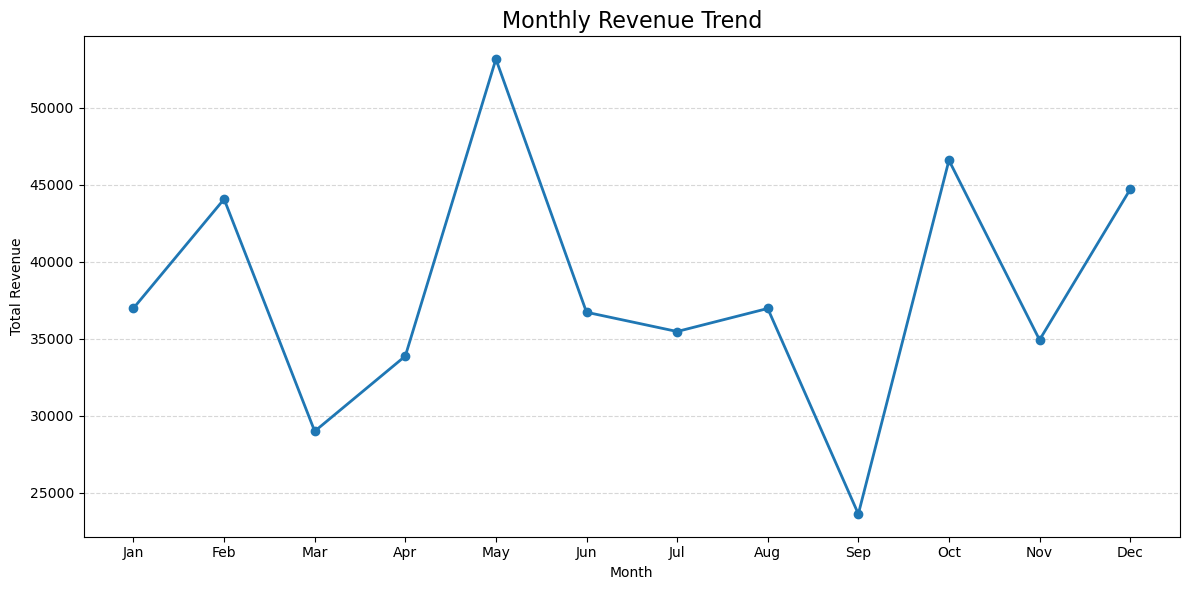

In [100]:
import matplotlib.pyplot as plt

months = [
    'Jan', 'Feb', 'Mar', 'Apr',
    'May', 'Jun', 'Jul', 'Aug',
    'Sep', 'Oct', 'Nov', 'Dec'
]

plt.figure(figsize=(12, 6))

plt.plot(
    months,
    monthly_revenue.values,
    marker='o',
    linewidth=2
)

plt.title('Monthly Revenue Trend', fontsize=16)
plt.xlabel('Month')
plt.ylabel('Total Revenue')

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [101]:
highest_month = monthly_revenue.idxmax()
lowest_month = monthly_revenue.idxmin()

print("Highest Revenue Month:", months[highest_month - 1])
print("Highest Revenue:", monthly_revenue.max())

print("Lowest Revenue Month:", months[lowest_month - 1])
print("Lowest Revenue:", monthly_revenue.min())

Highest Revenue Month: May
Highest Revenue: 53150
Lowest Revenue Month: Sep
Lowest Revenue: 23620


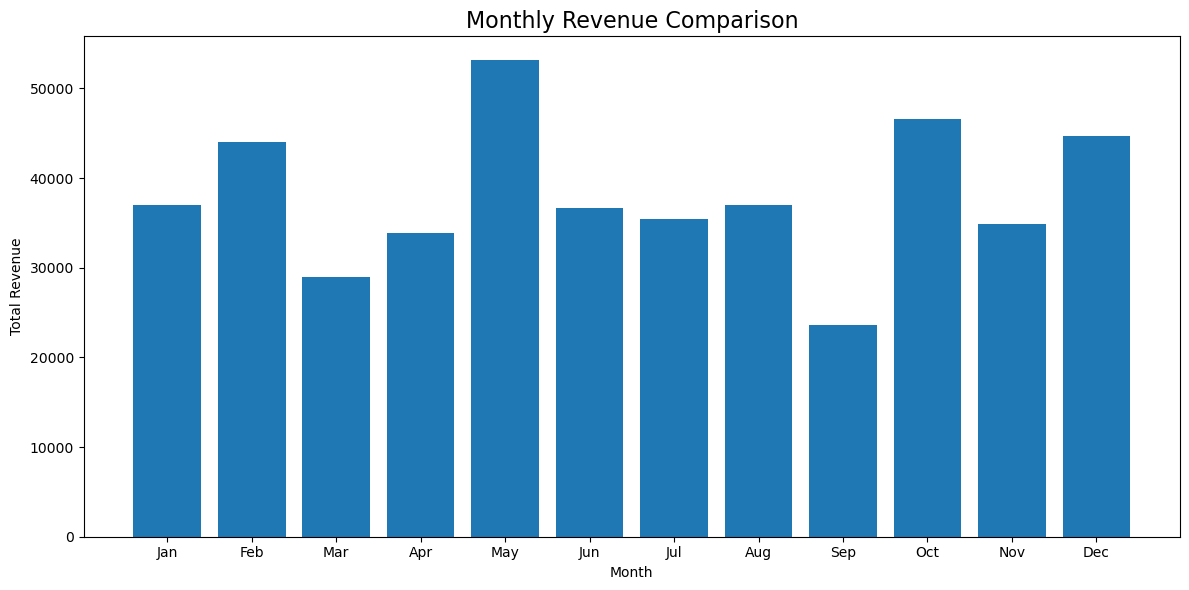

In [102]:
plt.figure(figsize=(12, 6))

plt.bar(months, monthly_revenue.values)

plt.title('Monthly Revenue Comparison', fontsize=16)
plt.xlabel('Month')
plt.ylabel('Total Revenue')

plt.tight_layout()
plt.show()

In [103]:
category_revenue = df_eda.groupby(
    'Product Category'
)['Total Amount'].sum()

print(category_revenue)

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64


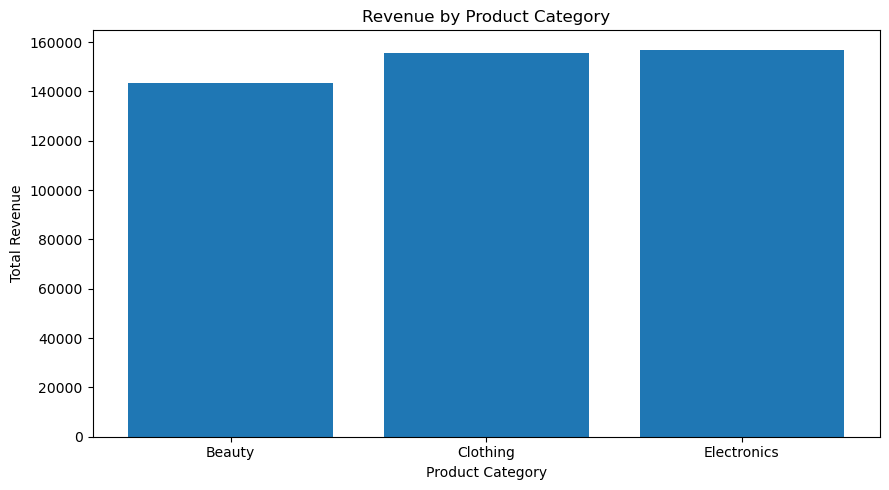

In [104]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(category_revenue.index, category_revenue.values)

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')

plt.tight_layout()
plt.show()

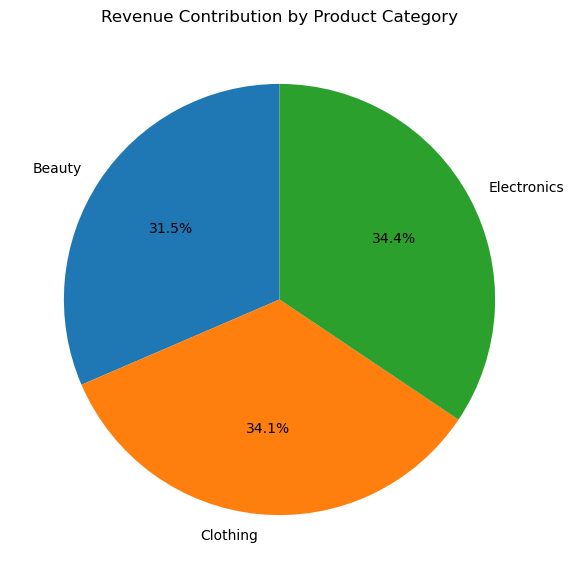

In [105]:
plt.figure(figsize=(7, 7))

plt.pie(
    category_revenue,
    labels=category_revenue.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Revenue Contribution by Product Category')
plt.show()

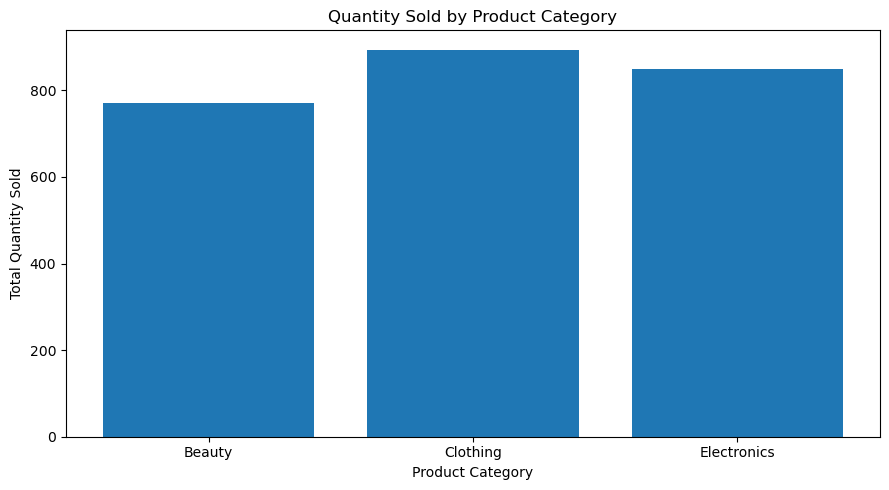

In [107]:
category_quantity = df_eda.groupby(
    'Product Category'
)['Quantity'].sum()

plt.figure(figsize=(9, 5))

plt.bar(category_quantity.index, category_quantity.values)

plt.title('Quantity Sold by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity Sold')

plt.tight_layout()
plt.show()

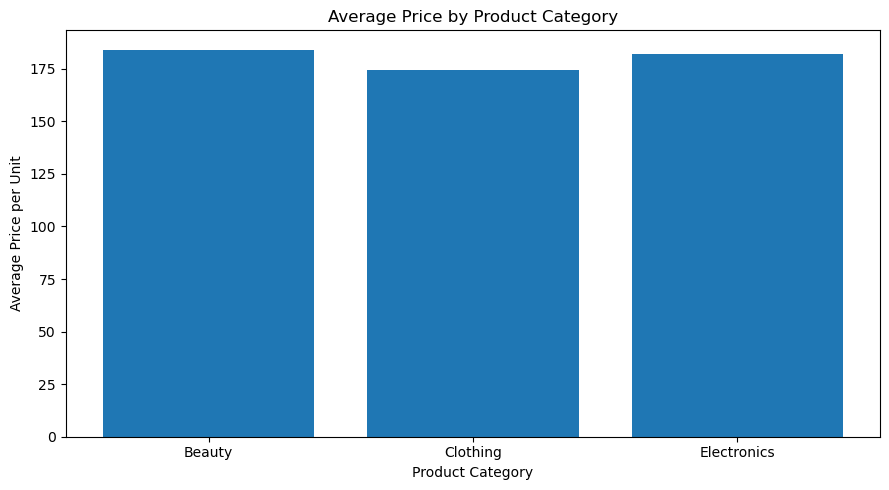

In [108]:
category_price = df_eda.groupby(
    'Product Category'
)['Price per Unit'].mean()

plt.figure(figsize=(9, 5))

plt.bar(category_price.index, category_price.values)

plt.title('Average Price by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Average Price per Unit')

plt.tight_layout()
plt.show()

In [109]:
gender_revenue = df_eda.groupby(
    'Gender'
)['Total Amount'].sum()

print(gender_revenue)


Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


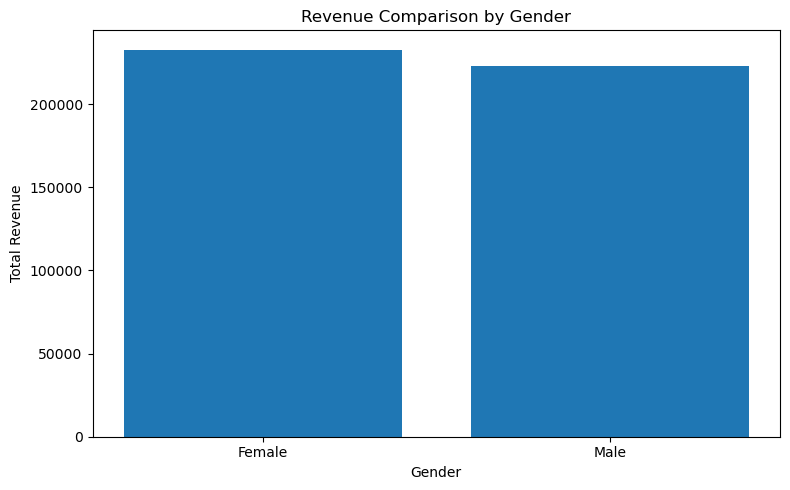

In [110]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(gender_revenue.index, gender_revenue.values)

plt.title('Revenue Comparison by Gender')
plt.xlabel('Gender')
plt.ylabel('Total Revenue')

plt.tight_layout()
plt.show()

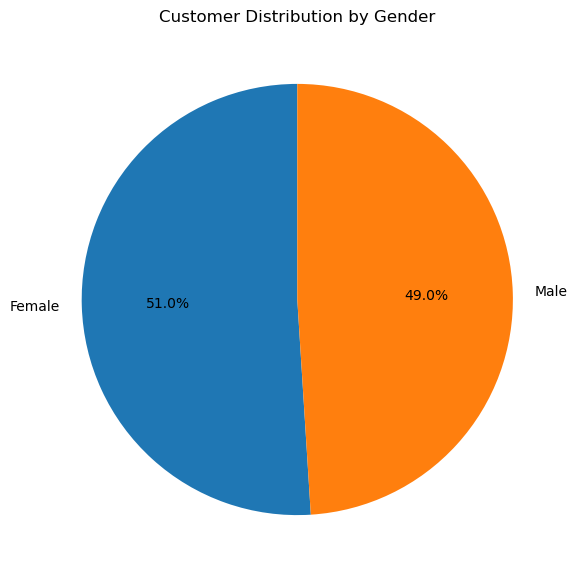

In [111]:
gender_count = df_eda['Gender'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    gender_count,
    labels=gender_count.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Distribution by Gender')
plt.show()

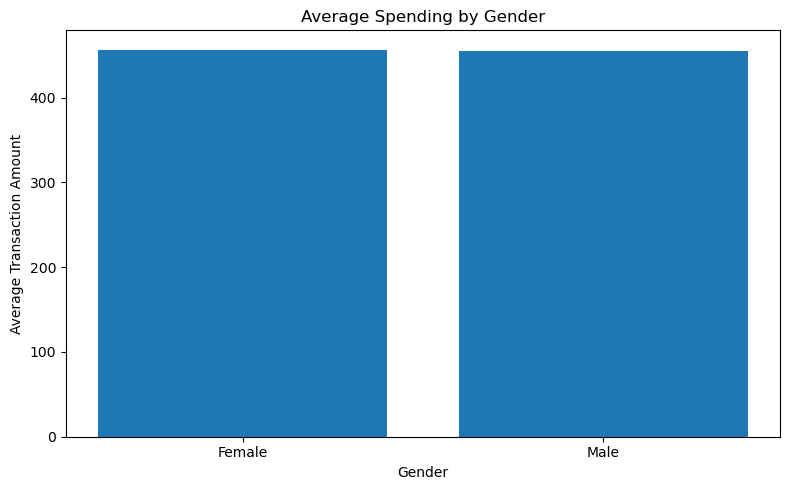

In [112]:
gender_average = df_eda.groupby(
    'Gender'
)['Total Amount'].mean()

plt.figure(figsize=(8, 5))

plt.bar(gender_average.index, gender_average.values)

plt.title('Average Spending by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Transaction Amount')

plt.tight_layout()
plt.show()

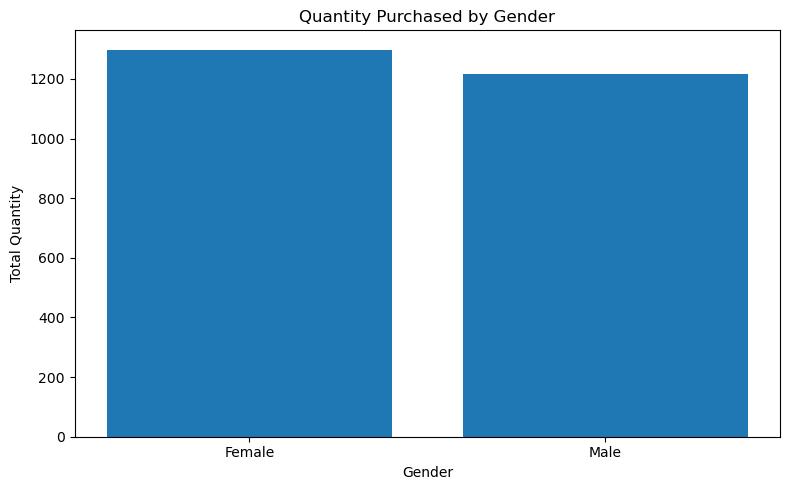

In [113]:
gender_quantity = df_eda.groupby(
    'Gender'
)['Quantity'].sum()

plt.figure(figsize=(8, 5))

plt.bar(gender_quantity.index, gender_quantity.values)

plt.title('Quantity Purchased by Gender')
plt.xlabel('Gender')
plt.ylabel('Total Quantity')

plt.tight_layout()
plt.show()

In [114]:
age_count = df_eda['Age Group'].value_counts().sort_index()

print(age_count)

Age Group
18-25    169
26-35    205
36-45    202
46-55    229
56-64    195
Name: count, dtype: int64


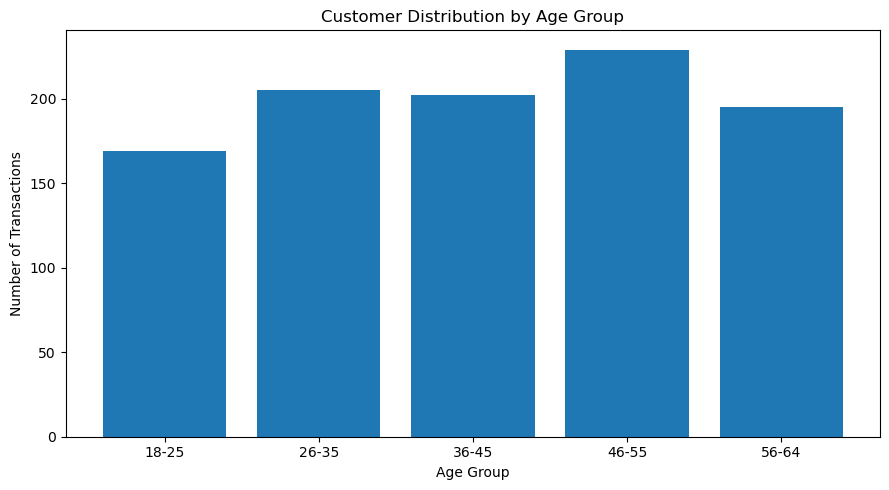

In [115]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(age_count.index.astype(str), age_count.values)

plt.title('Customer Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Transactions')

plt.tight_layout()
plt.show()

In [116]:
age_revenue = df_eda.groupby(
    'Age Group', observed=False
)['Total Amount'].sum()

print(age_revenue)

Age Group
18-25     84550
26-35     98480
36-45     91870
46-55    100690
56-64     80410
Name: Total Amount, dtype: int64


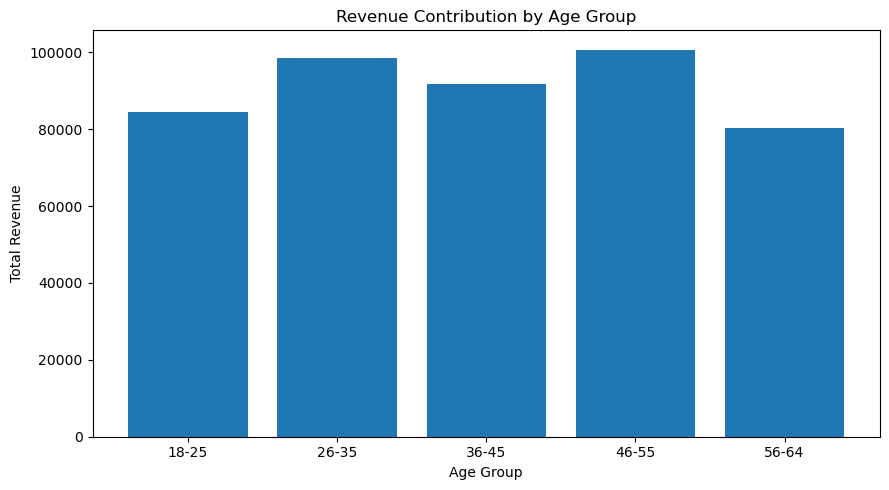

In [117]:
plt.figure(figsize=(9, 5))

plt.bar(age_revenue.index.astype(str), age_revenue.values)

plt.title('Revenue Contribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Total Revenue')

plt.tight_layout()
plt.show()

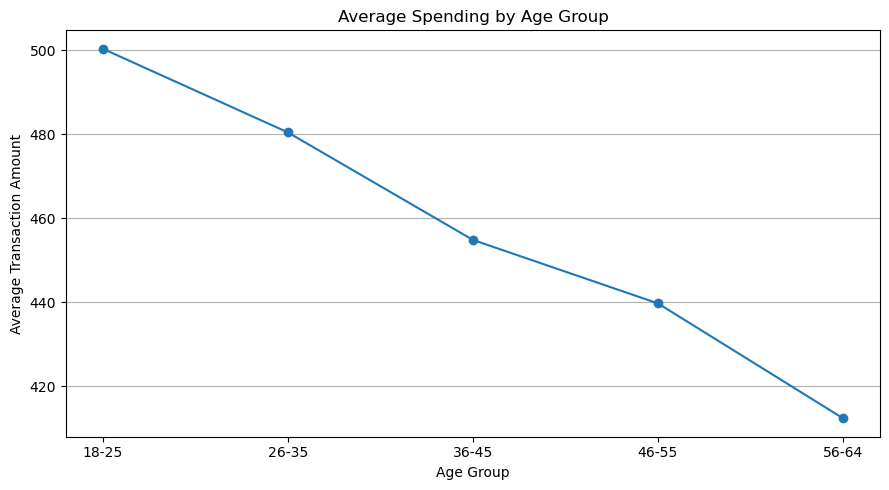

In [118]:
age_average = df_eda.groupby(
    'Age Group', observed=False
)['Total Amount'].mean()

plt.figure(figsize=(9, 5))

plt.plot(
    age_average.index.astype(str),
    age_average.values,
    marker='o'
)

plt.title('Average Spending by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Transaction Amount')

plt.grid(axis='y')
plt.tight_layout()
plt.show()

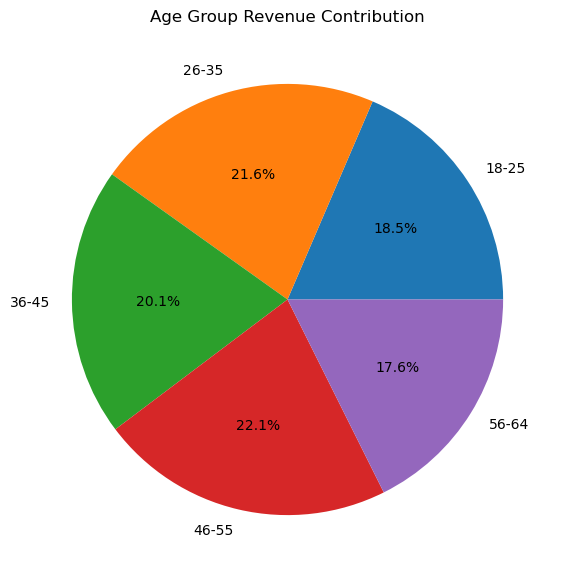

In [119]:
age_revenue.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(7, 7)
)

plt.title('Age Group Revenue Contribution')
plt.ylabel('')
plt.show()

In [120]:
df['Day'] = df['Date'].dt.day_name()

day_sales = df.groupby('Day')['Total Amount'].sum()

day_sales

Day
Friday       66290
Monday       70250
Saturday     78815
Sunday       58600
Thursday     53835
Tuesday      69440
Wednesday    58770
Name: Total Amount, dtype: int64

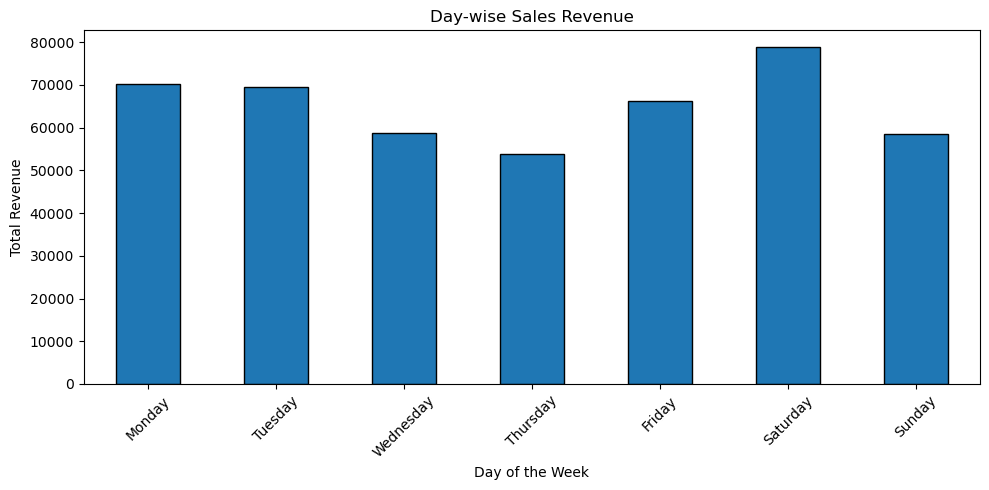

In [121]:
import matplotlib.pyplot as plt

week_order = ['Monday', 'Tuesday', 'Wednesday',
              'Thursday', 'Friday', 'Saturday', 'Sunday']

day_sales = day_sales.reindex(week_order)

day_sales.plot(
    kind='bar',
    figsize=(10, 5),
    edgecolor='black'
)

plt.title('Day-wise Sales Revenue')
plt.xlabel('Day of the Week')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [122]:
sales_trend = df.groupby('Date')['Total Amount'].sum()

sales_trend = sales_trend.sort_index()

sales_trend.head()

Date
2023-01-01    3600
2023-01-02    1765
2023-01-03     600
2023-01-04    1240
2023-01-05    1100
Name: Total Amount, dtype: int64

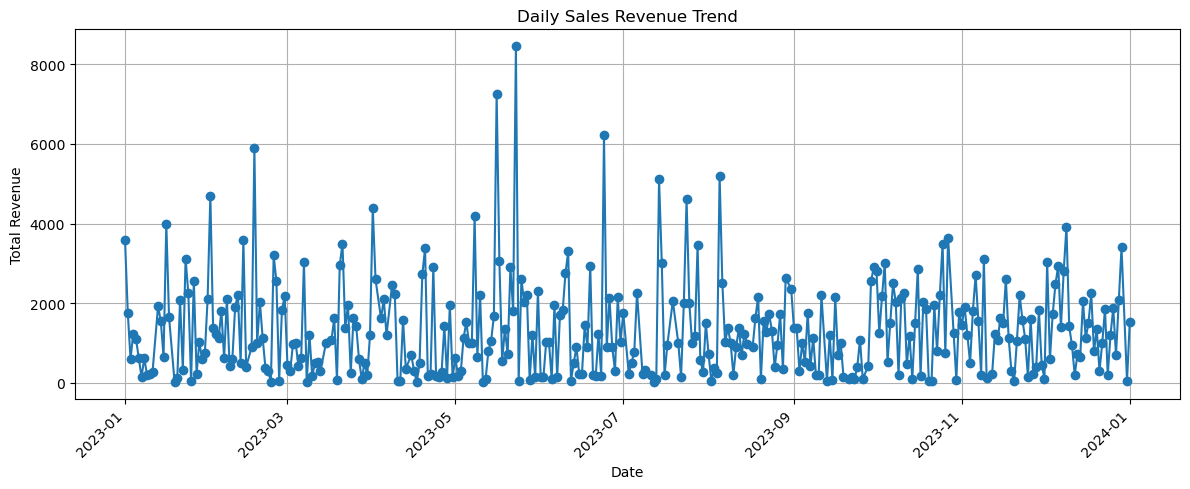

In [123]:
plt.figure(figsize=(12, 5))

sales_trend.plot(
    kind='line',
    marker='o'
)

plt.title('Daily Sales Revenue Trend')
plt.xlabel('Date')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [124]:
category_quantity = df.groupby('Product Category')['Quantity'].sum()

category_quantity.sort_values(ascending=False)

Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64

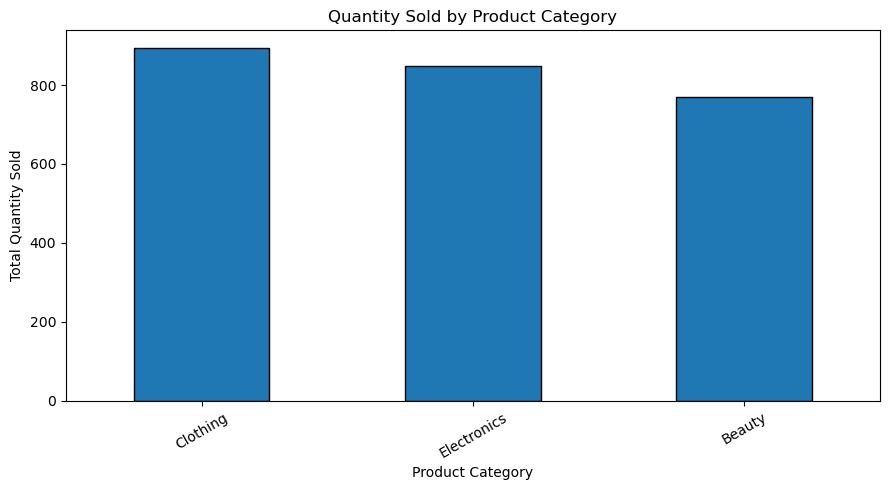

In [125]:
category_quantity.sort_values(ascending=False).plot(
    kind='bar',
    figsize=(9, 5),
    edgecolor='black'
)

plt.title('Quantity Sold by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [126]:
gender_sales = df.groupby('Gender')['Total Amount'].sum()

gender_sales

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64

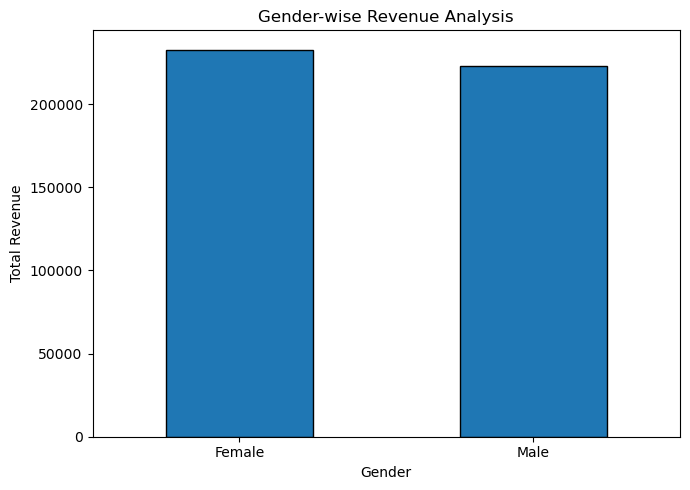

In [127]:
gender_sales.plot(
    kind='bar',
    figsize=(7, 5),
    edgecolor='black'
)

plt.title('Gender-wise Revenue Analysis')
plt.xlabel('Gender')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [129]:
df.columns

Index(['Date', 'Gender', 'Age', 'Product Category', 'Quantity',
       'Price per Unit', 'Total Amount', 'Day'],
      dtype='object')

In [130]:
bins = [0, 18, 25, 35, 45, 55, 100]

labels = ['Below 18', '18-25', '26-35',
          '36-45', '46-55', 'Above 55']

df['Age Group'] = pd.cut(
    df['Age'],
    bins=bins,
    labels=labels
)

df[['Age', 'Age Group']].head()


,Age,Age Group
0,34,26-35
1,26,26-35
2,50,46-55
3,37,36-45
4,30,26-35


In [131]:
age_group_count = df.groupby('Age Group', observed=False).size()

age_group_count

Age Group
Below 18     21
18-25       148
26-35       205
36-45       202
46-55       229
Above 55    195
dtype: int64

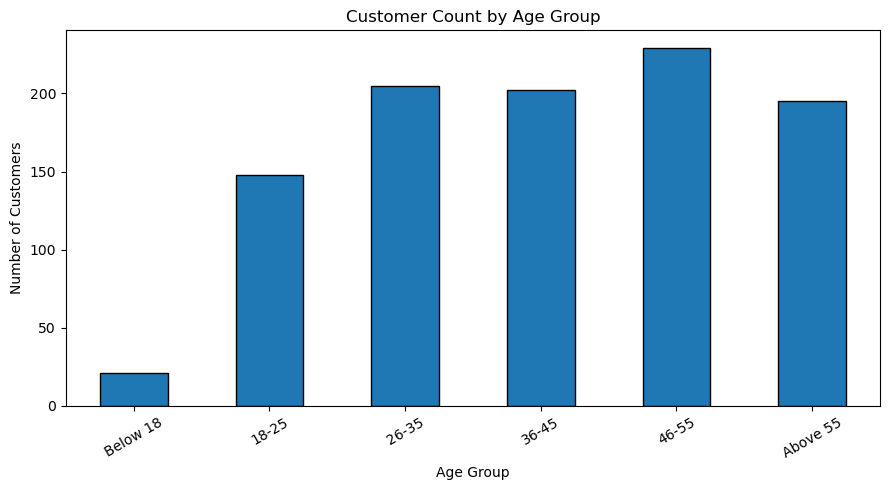

In [132]:
age_group_count.plot(
    kind='bar',
    figsize=(9, 5),
    edgecolor='black'
)

plt.title('Customer Count by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [133]:
category_avg_spending = df.groupby('Product Category')['Total Amount'].mean()

category_avg_spending.sort_values(ascending=False)

Product Category
Beauty         467.475570
Electronics    458.786550
Clothing       443.247863
Name: Total Amount, dtype: float64

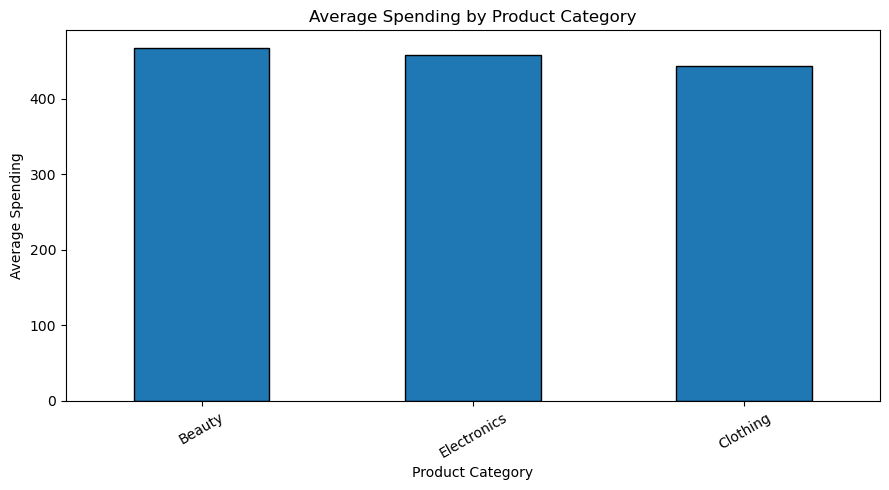

In [134]:
category_avg_spending.sort_values(ascending=False).plot(
    kind='bar',
    figsize=(9, 5),
    edgecolor='black'
)

plt.title('Average Spending by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Average Spending')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [135]:
df['Month'] = df['Date'].dt.month_name()

monthly_transactions = df.groupby('Month').size()

monthly_transactions

Month
April         86
August        94
December      91
February      85
January       78
July          72
June          77
March         73
May          105
November      78
October       96
September     65
dtype: int64

In [136]:
month_order = ['January', 'February', 'March', 'April',
               'May', 'June', 'July', 'August',
               'September', 'October', 'November', 'December']

monthly_transactions = monthly_transactions.reindex(month_order)

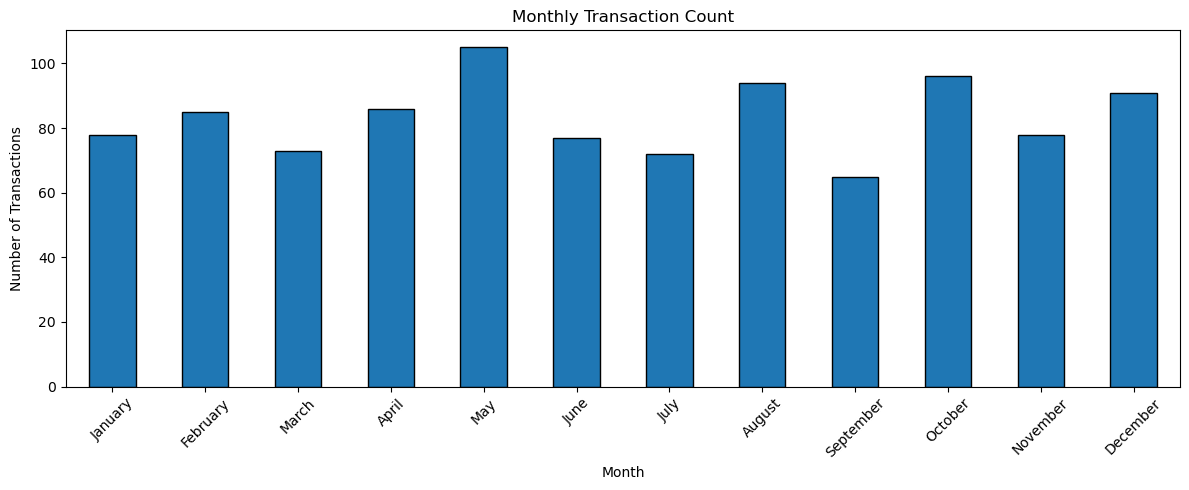

In [137]:
monthly_transactions.plot(
    kind='bar',
    figsize=(12, 5),
    edgecolor='black'
)

plt.title('Monthly Transaction Count')
plt.xlabel('Month')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [138]:
df['Total Amount'].describe()

count    1000.000000
mean      456.000000
std       559.997632
min        25.000000
25%        60.000000
50%       135.000000
75%       900.000000
max      2000.000000
Name: Total Amount, dtype: float64

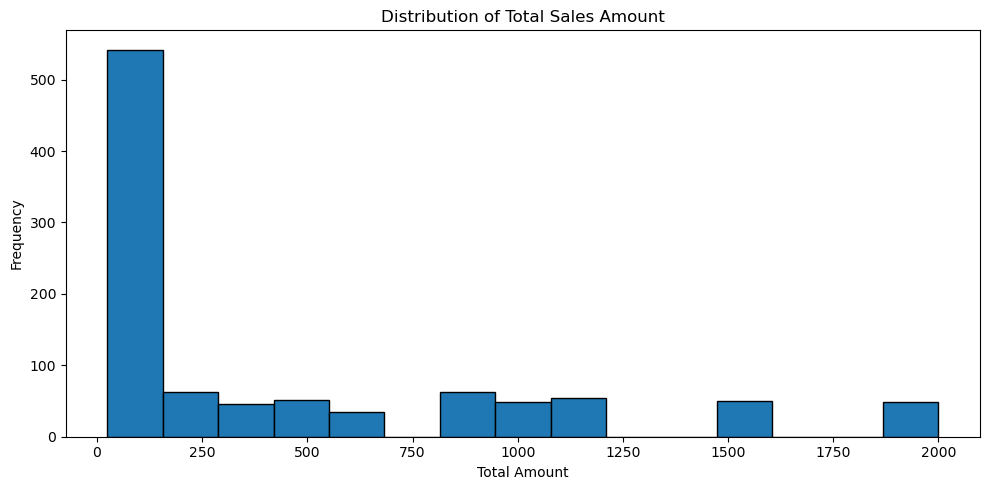

In [139]:
plt.figure(figsize=(10, 5))

plt.hist(
    df['Total Amount'],
    bins=15,
    edgecolor='black'
)

plt.title('Distribution of Total Sales Amount')
plt.xlabel('Total Amount')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [140]:
avg_unit_price = df.groupby('Product Category')['Price per Unit'].mean()

avg_unit_price.sort_values(ascending=False)

Product Category
Beauty         184.055375
Electronics    181.900585
Clothing       174.287749
Name: Price per Unit, dtype: float64

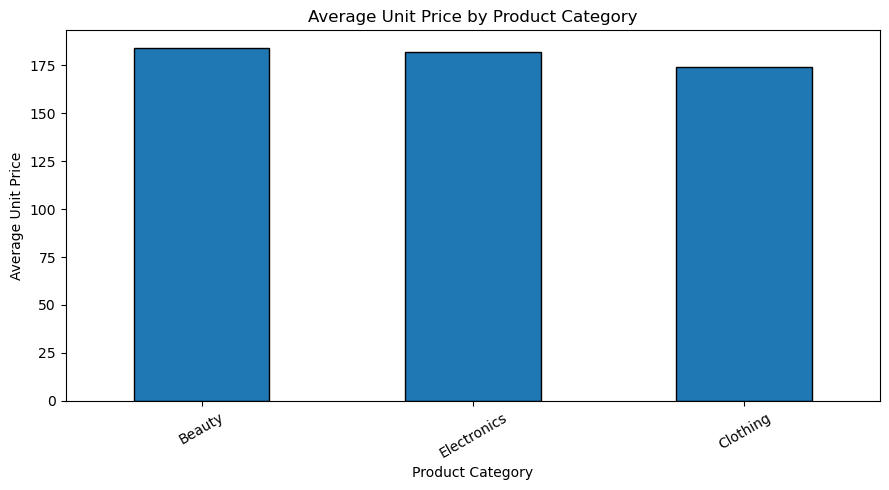

In [141]:
avg_unit_price.sort_values(ascending=False).plot(
    kind='bar',
    figsize=(9, 5),
    edgecolor='black'
)

plt.title('Average Unit Price by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Average Unit Price')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()